In [2]:
import sys
import os
sys.path.insert(0, os.path.abspath("../.."))

In [3]:
import json
import gzip
from os import path
from collections import defaultdict
import glob
import pandas as pd
import matplotlib.pyplot as plt

from compounds_research import settings
from compounds_research import utils

In [4]:
with open(path.join(settings.DATA_PATH, "compound", "contracts.json")) as f:
    contracts = json.load(f)
address_to_name = {c["address"]: c["name"] for c in contracts}
name_to_address = {c["name"]: c["address"] for c in contracts}

In [5]:
def load_events():
    events = []
    for filename in glob.glob(path.join(settings.DATA_PATH, "compound", "events", "*.jsonl.gz")):
        print("loading", filename)
        name = path.basename(filename).split(".")[0]
        with gzip.open(filename) as f:
            for line in f:
                event = json.loads(line)
                if not "event" in event:
                    continue
                events.append(event)
    return events

In [6]:
def save_plot(name):
    filename = path.join(settings.FIGURES_PATH, name)
    plt.savefig(filename)

In [7]:
def compute_balances():
    balances = {asset: defaultdict(int) for asset in name_to_address}
    for event in events:
        asset = address_to_name[event["address"].lower()]
        users = balances[asset]
        if event["event"] == "Transfer":
            if event["address"] != event["returnValues"]["from"]:
                users[event["returnValues"]["from"]] -= int(event["returnValues"]["amount"])
            if event["address"] != event["returnValues"]["to"]:
                users[event["returnValues"]["to"]] += int(event["returnValues"]["amount"])
    return {k: sorted(v.items(), key=lambda x: -x[1]) for k, v in balances.items()}
#     if event["event"] == "Mint":
#         users[event["returnValues"]["minter"]] += int(event["returnValues"]["mintTokens"])
#     if event["event"] == "Redeem":
#         users[event["returnValues"]["redeemer"]] -= int(event["returnValues"]["redeemTokens"])
#     if event["event"] == "LiquidateBorrow":
#         collateral_asset = address_to_name[event["returnValues"]["cTokenCollateral"].lower()]
#         collateral_users = balances[collateral_asset]
#         seize_tokens = int(event["returnValues"]["seizeTokens"])
#         collateral_users[event["returnValues"]["liquidator"]] += seize_tokens
#         collateral_users[event["returnValues"]["borrower"]] -= seize_tokens

In [8]:
events = load_events()
print("#events", len(events))

loading /Users/wangluyao/defi-plf-analysis/data/compound/events/cwbtc.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/cdai.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/cbat.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/cusdc.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/csai.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/ceth.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/czrx.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/crep.jsonl.gz
loading /Users/wangluyao/defi-plf-analysis/data/compound/events/cusdt.jsonl.gz
#events 1429981


In [9]:
balances = compute_balances()
balances["cdai"][:10]

[('0x41122F2Bf6edc3Dfb6BF148000e3900C28d38004', 1008664072401699237),
 ('0xccB06B8026CB33Ee501476aF87d5CCAF56883112', 386223811890469035),
 ('0x3BA21b6477F48273f41d241AA3722FFb9E07E247', 368645391203529049),
 ('0x2C101E1cFE5cC0d0a948f802059c43723AD90175', 303834233794852193),
 ('0x96d480f112FCb02F0Be233bfBdac12434412148c', 276750770958539284),
 ('0x7146D797A9e8eb8C1b153C01aEBCCba2Dc695044', 273152923815845443),
 ('0x4960170D73F32F6E28302CD3F356E284034F2880', 205386107021551396),
 ('0x909b443761bbD7fbB876Ecde71a37E1433f6af6f', 197060085515542818),
 ('0xf7bCD7bB00f4D081775FedEF64e92017a10d4b25', 195597126479599394),
 ('0x25599DCbd434aF9A17D52444f71c92987fa97cfC', 118271755796942497)]

In [10]:
mint = [e for e in events if e["event"] == "Mint" and address_to_name[e["address"].lower()] == "cdai"][0]
values = mint["returnValues"]
int(values["mintAmount"]) / int(values["mintTokens"]) / 1e9

0.2056393501247215

/Users/wangluyao/defi-plf-analysis/compounds_research/utils.py:136: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["{0}%".format(int(v * 100)) for v in ax.get_yticks()])


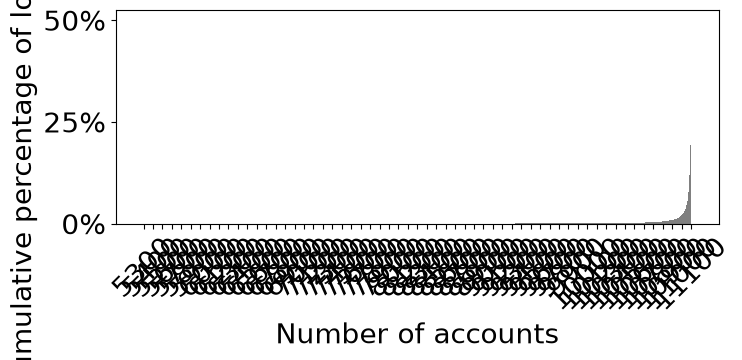

In [11]:
cdai_balances = [v[1] for v in balances["cdai"]]
# this skips accounts until combined sum is roughly 1%
# otherwise there are too many values near 0
utils.plot_cumulative_hist(cdai_balances, skip_count=5300, ticks_interval=100)
save_plot('cdai-cum-wealth.pdf')

/Users/wangluyao/defi-plf-analysis/compounds_research/utils.py:136: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["{0}%".format(int(v * 100)) for v in ax.get_yticks()])


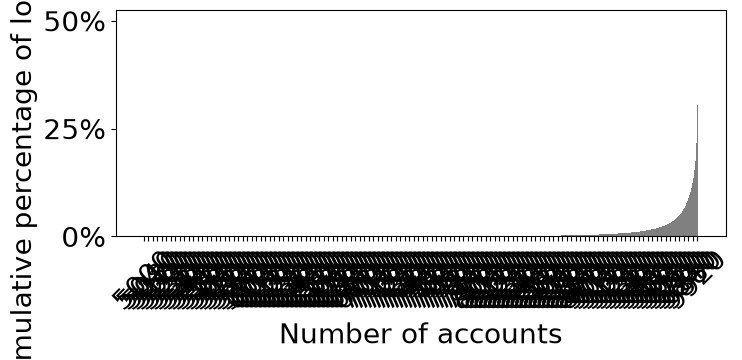

In [12]:
ceth_balances = [v[1] for v in balances["ceth"]]
utils.plot_cumulative_hist(ceth_balances, skip_count=5000, ticks_interval=40)
save_plot('ceth-cum-wealth.pdf')

/Users/wangluyao/defi-plf-analysis/compounds_research/utils.py:136: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["{0}%".format(int(v * 100)) for v in ax.get_yticks()])


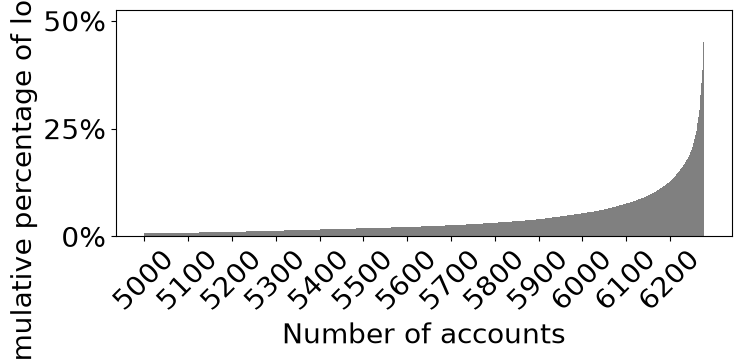

In [13]:
csai_balances = [v[1] for v in balances["csai"]]
utils.plot_cumulative_hist(csai_balances, skip_count=5000, ticks_interval=100)
save_plot('csai-cum-wealth.pdf')

/Users/wangluyao/defi-plf-analysis/compounds_research/utils.py:136: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["{0}%".format(int(v * 100)) for v in ax.get_yticks()])


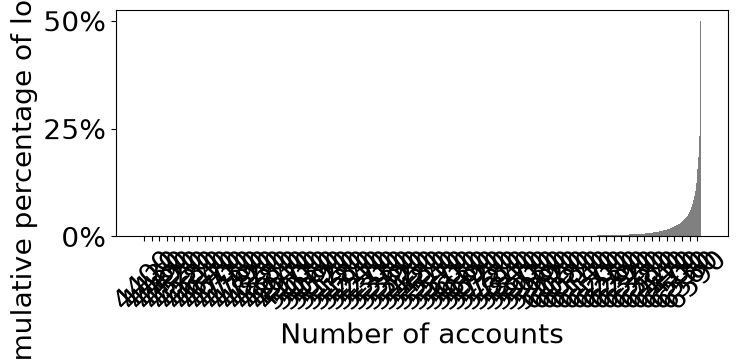

In [14]:
cusdc_balances = [v[1] for v in balances["cusdc"]]
utils.plot_cumulative_hist(cusdc_balances, skip_count=4400, ticks_interval=30)
save_plot('cusdc-cum-wealth.pdf')